# Deep Learning Lab — CNN Visualization, Parameter Audit & Critical Analysis

**Based on the lab manual:**  
1. Five custom 3×3 filters  
2. Four stages for each filter: Raw Convolution → ReLU → 2×2 Max Pooling → 2×2 Average Pooling  
3. A unified **5 × 4 visualization grid**  
4. Model A (3×3 + Max Pooling) and Model B (5×5 + Average Pooling)  
5. Manual parameter audit + framework `model.summary()`  
6. Numerical evidence to help answer Critical Thinking Questions 1–5

**Google Colab:** Run the cells from top to bottom. When asked, upload a clear RGB/grayscale image with strong edges and textures (a building image is a good choice).

In [1]:
# ============================================================
# CELL 1 — Imports and setup
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve2d
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from google.colab import files
from PIL import Image
import io

np.set_printoptions(precision=3, suppress=True)

print("TensorFlow version:", tf.__version__)
print("Ready.")


TensorFlow version: 2.21.0
Ready.


## Part I — Select and prepare the input image

The manual asks for a clear grayscale or RGB image containing distinct geometric edges, textures, and contrast gradients.

Saving OIP.webp to OIP.webp
Image: OIP.webp
Image size used for filtering: (180, 312)


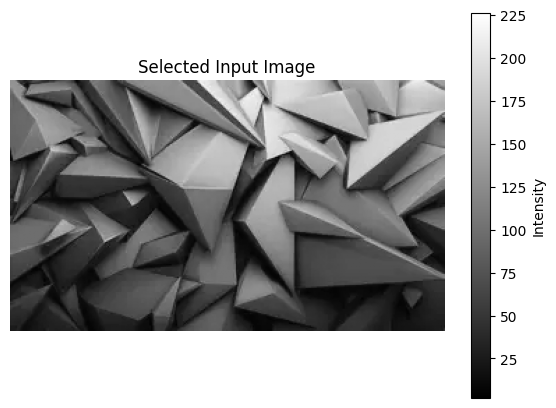

In [2]:
# ============================================================
# CELL 2 — Upload image
# ============================================================
uploaded = files.upload()

if not uploaded:
    raise ValueError("No image was uploaded.")

filename = next(iter(uploaded))
img = Image.open(io.BytesIO(uploaded[filename])).convert("RGB")

# Convert to grayscale for the custom spatial-filter visualization.
gray = np.asarray(img.convert("L"), dtype=np.float32)

# Keep the image manageable for Colab and visualization.
MAX_SIZE = 512
if max(gray.shape) > MAX_SIZE:
    scale = MAX_SIZE / max(gray.shape)
    new_size = (int(gray.shape[1] * scale), int(gray.shape[0] * scale))
    gray = np.asarray(Image.fromarray(gray.astype(np.uint8)).resize(new_size), dtype=np.float32)

print("Image:", filename)
print("Image size used for filtering:", gray.shape)

plt.figure(figsize=(7,5))
plt.imshow(gray, cmap="gray")
plt.title("Selected Input Image")
plt.axis("off")
plt.colorbar(label="Intensity")
plt.show()


## Five required 3×3 kernels

The five filters required by the manual are:
- Horizontal edge detector
- Vertical edge detector
- Sharpen
- Box/Gaussian blur
- Emboss

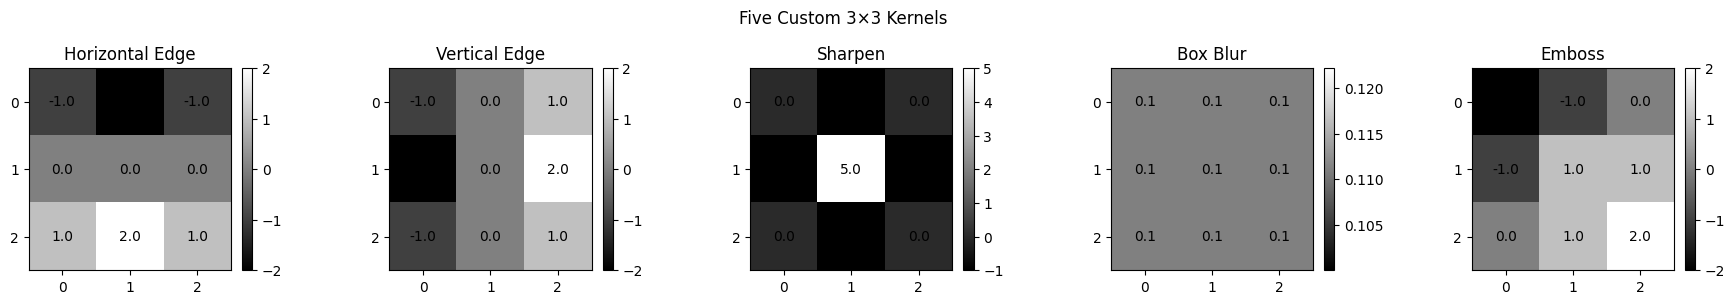

In [3]:
# ============================================================
# CELL 3 — Define the five required 3×3 kernels
# ============================================================

kernels = {
    "Horizontal Edge": np.array([
        [-1, -2, -1],
        [ 0,  0,  0],
        [ 1,  2,  1]
    ], dtype=np.float32),

    "Vertical Edge": np.array([
        [-1,  0,  1],
        [-2,  0,  2],
        [-1,  0,  1]
    ], dtype=np.float32),

    "Sharpen": np.array([
        [ 0, -1,  0],
        [-1,  5, -1],
        [ 0, -1,  0]
    ], dtype=np.float32),

    # Box blur is explicitly allowed by the manual's
    # "Box/Gaussian Blur Kernel" requirement.
    "Box Blur": np.ones((3, 3), dtype=np.float32) / 9.0,

    "Emboss": np.array([
        [-2, -1,  0],
        [-1,  1,  1],
        [ 0,  1,  2]
    ], dtype=np.float32)
}

fig, axes = plt.subplots(1, 5, figsize=(18, 3))
for ax, (name, kernel) in zip(axes, kernels.items()):
    im = ax.imshow(kernel, cmap="gray")
    ax.set_title(name)
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    for r in range(3):
        for c in range(3):
            ax.text(c, r, f"{kernel[r,c]:.1f}", ha="center", va="center")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle("Five Custom 3×3 Kernels")
plt.tight_layout()
plt.show()


## Sequential pipeline

For each filter:
- **Stage A:** Raw convolution output
- **Stage B:** ReLU = `max(0, x)`
- **Stage C:** 2×2 Max Pooling, stride 2, applied to Stage B
- **Stage D:** 2×2 Average Pooling, stride 2, applied to Stage B

Both pooling operations start from the same Post-ReLU feature map, as required by the manual.

In [4]:
# ============================================================
# CELL 4 — Run all five filters through all four stages
# ============================================================

def relu(x):
    return np.maximum(0, x)

def pool_2x2(x, mode="max"):
    h, w = x.shape
    h2 = h - (h % 2)
    w2 = w - (w % 2)
    x = x[:h2, :w2]

    # Non-overlapping 2x2 pooling, stride 2.
    blocks = x.reshape(h2 // 2, 2, w2 // 2, 2)

    if mode == "max":
        return blocks.max(axis=(1, 3))
    elif mode == "avg":
        return blocks.mean(axis=(1, 3))
    else:
        raise ValueError("mode must be 'max' or 'avg'")

results = {}

for name, kernel in kernels.items():
    raw = convolve2d(gray, kernel, mode="same", boundary="symm")
    relu_map = relu(raw)
    max_pool = pool_2x2(relu_map, mode="max")
    avg_pool = pool_2x2(relu_map, mode="avg")

    results[name] = {
        "A_raw": raw,
        "B_relu": relu_map,
        "C_maxpool": max_pool,
        "D_avgpool": avg_pool
    }

print("Pipeline completed for all 5 filters.")
for name, maps in results.items():
    print(f"{name:18s}:", {k: v.shape for k, v in maps.items()})


Pipeline completed for all 5 filters.
Horizontal Edge   : {'A_raw': (180, 312), 'B_relu': (180, 312), 'C_maxpool': (90, 156), 'D_avgpool': (90, 156)}
Vertical Edge     : {'A_raw': (180, 312), 'B_relu': (180, 312), 'C_maxpool': (90, 156), 'D_avgpool': (90, 156)}
Sharpen           : {'A_raw': (180, 312), 'B_relu': (180, 312), 'C_maxpool': (90, 156), 'D_avgpool': (90, 156)}
Box Blur          : {'A_raw': (180, 312), 'B_relu': (180, 312), 'C_maxpool': (90, 156), 'D_avgpool': (90, 156)}
Emboss            : {'A_raw': (180, 312), 'B_relu': (180, 312), 'C_maxpool': (90, 156), 'D_avgpool': (90, 156)}


## Required 5 × 4 visualization grid

This produces the main evidence figure required by the lab manual: **5 rows × 4 columns**, with titles and colorbars/intensity scales.

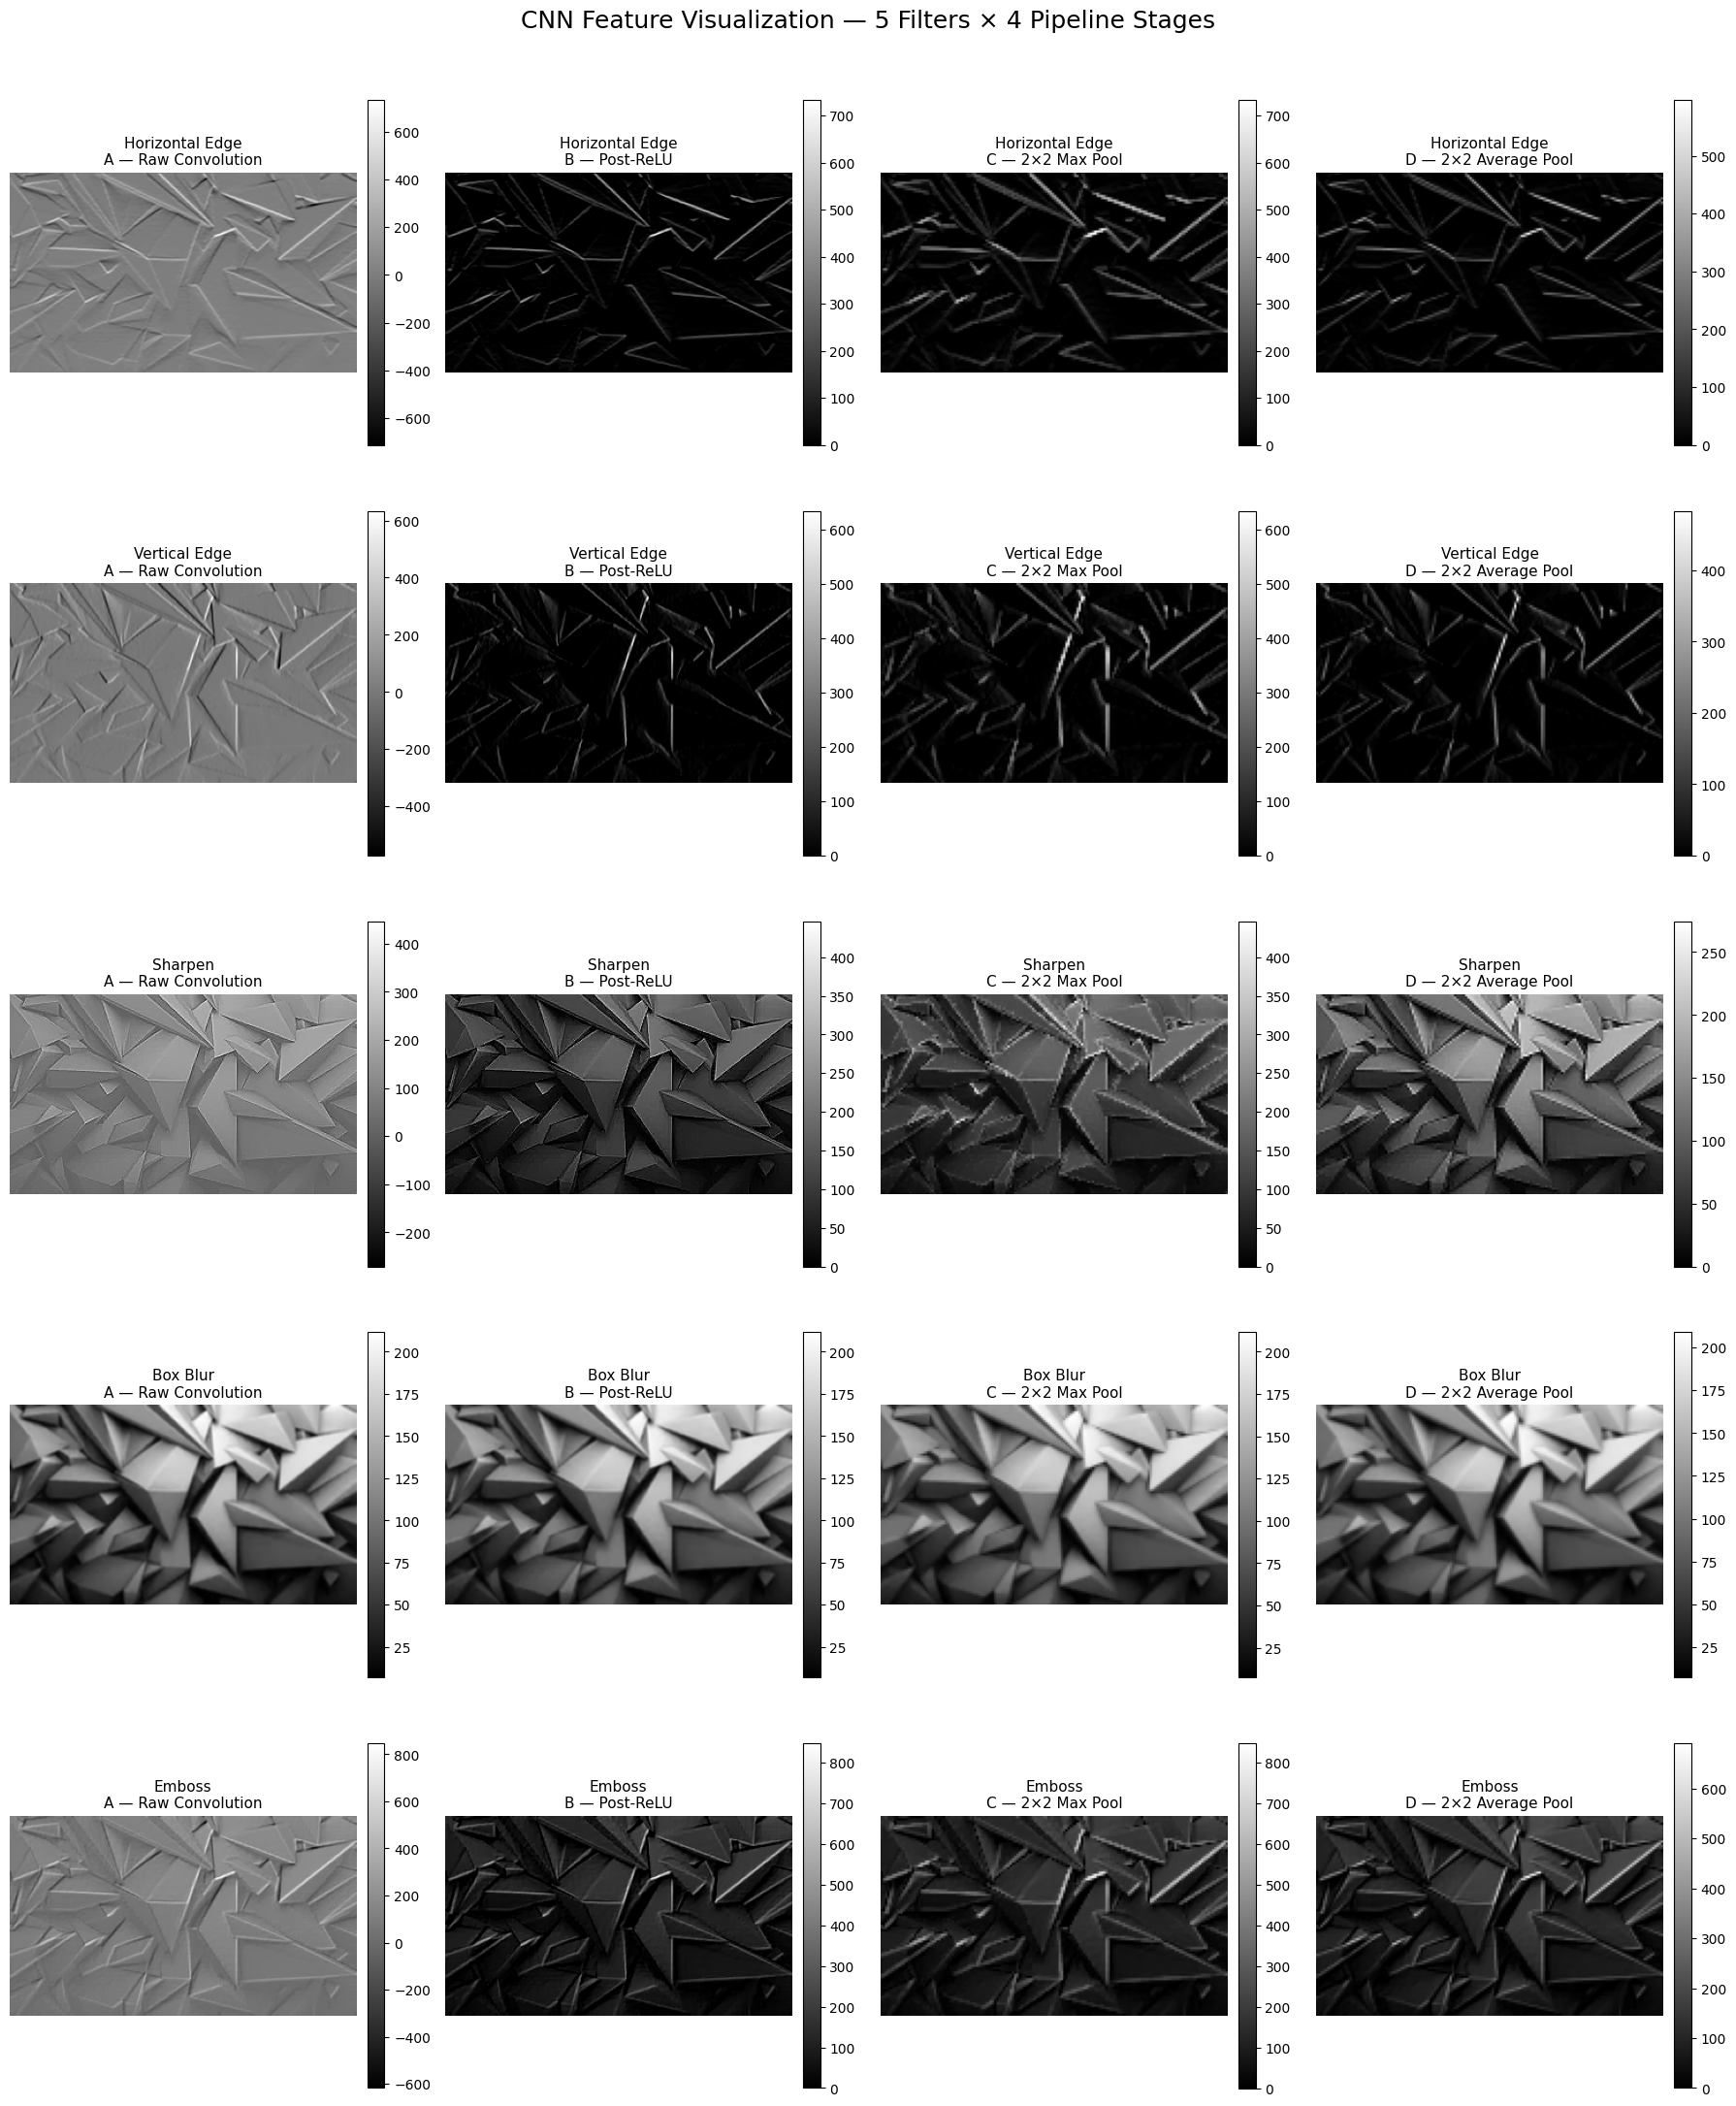

Saved: CNN_5x4_Visualization_Grid.png


In [5]:
# ============================================================
# CELL 5 — Required 5 × 4 visualization grid
# ============================================================

stage_names = [
    ("A — Raw Convolution", "A_raw"),
    ("B — Post-ReLU", "B_relu"),
    ("C — 2×2 Max Pool", "C_maxpool"),
    ("D — 2×2 Average Pool", "D_avgpool")
]

filter_names = list(kernels.keys())

fig, axes = plt.subplots(5, 4, figsize=(18, 22))

for row, filter_name in enumerate(filter_names):
    for col, (title, key) in enumerate(stage_names):
        ax = axes[row, col]
        data = results[filter_name][key]

        im = ax.imshow(data, cmap="gray")
        ax.set_title(f"{filter_name}\n{title}", fontsize=11)
        ax.axis("off")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)

plt.suptitle("CNN Feature Visualization — 5 Filters × 4 Pipeline Stages",
             fontsize=18, y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.99])

# Save the required figure for the report.
plt.savefig("CNN_5x4_Visualization_Grid.png", dpi=200, bbox_inches="tight")
plt.show()

print("Saved: CNN_5x4_Visualization_Grid.png")


## Useful numerical evidence from Part I

These values help you write the critical-analysis answers using **your own generated feature maps** rather than generic statements.

In [6]:
# ============================================================
# CELL 6 — Evidence/statistics for Questions 1 and 2
# ============================================================

print("=" * 75)
print("PART I NUMERICAL EVIDENCE")
print("=" * 75)

for name in ["Horizontal Edge", "Vertical Edge", "Sharpen", "Box Blur", "Emboss"]:
    raw = results[name]["A_raw"]
    relu_map = results[name]["B_relu"]
    max_map = results[name]["C_maxpool"]
    avg_map = results[name]["D_avgpool"]

    negative_pct = np.mean(raw < 0) * 100
    zero_after_relu_pct = np.mean(relu_map == 0) * 100

    print(f"\n{name}")
    print(f"  Raw min/max              : {raw.min():.3f} / {raw.max():.3f}")
    print(f"  Negative raw pixels     : {negative_pct:.2f}%")
    print(f"  Zero pixels after ReLU  : {zero_after_relu_pct:.2f}%")
    print(f"  Max-pool mean/max       : {max_map.mean():.3f} / {max_map.max():.3f}")
    print(f"  Avg-pool mean/max       : {avg_map.mean():.3f} / {avg_map.max():.3f}")

# Compare Max vs Average pooling for edge/sharpen maps.
print("\n" + "=" * 75)
print("MAX POOLING VS AVERAGE POOLING — HIGH-RESPONSE COMPARISON")
print("=" * 75)

for name in ["Horizontal Edge", "Vertical Edge", "Sharpen"]:
    max_map = results[name]["C_maxpool"]
    avg_map = results[name]["D_avgpool"]

    print(f"\n{name}")
    print(f"  Max-pool maximum   = {max_map.max():.3f}")
    print(f"  Avg-pool maximum   = {avg_map.max():.3f}")
    print(f"  Max-pool mean      = {max_map.mean():.3f}")
    print(f"  Avg-pool mean      = {avg_map.mean():.3f}")
    print(f"  Max/Avg max ratio  = {max_map.max() / (avg_map.max() + 1e-8):.3f}")


PART I NUMERICAL EVIDENCE

Horizontal Edge
  Raw min/max              : -712.000 / 733.000
  Negative raw pixels     : 44.55%
  Zero pixels after ReLU  : 50.41%
  Max-pool mean/max       : 38.849 / 733.000
  Avg-pool mean/max       : 23.098 / 596.500

Vertical Edge
  Raw min/max              : -573.000 / 634.000
  Negative raw pixels     : 49.76%
  Zero pixels after ReLU  : 56.61%
  Max-pool mean/max       : 29.766 / 634.000
  Avg-pool mean/max       : 17.702 / 483.500

Sharpen
  Raw min/max              : -271.000 / 446.000
  Negative raw pixels     : 4.83%
  Zero pixels after ReLU  : 5.05%
  Max-pool mean/max       : 104.056 / 446.000
  Avg-pool mean/max       : 85.542 / 274.250

Box Blur
  Raw min/max              : 7.000 / 211.444
  Negative raw pixels     : 0.00%
  Zero pixels after ReLU  : 0.00%
  Max-pool mean/max       : 88.640 / 211.444
  Avg-pool mean/max       : 84.060 / 208.722

Emboss
  Raw min/max              : -618.000 / 847.000
  Negative raw pixels     : 9.75%
  Zero 

# Part II — Architectural Comparison & Parameter Audit

The manual specifies:

### Model A — Standard
- Input: 32×32×3
- Conv1: 5 filters, 3×3
- Conv2: 10 filters, 3×3
- 2×2 Max Pooling, stride 2
- Global Average Pooling
- Dense: 10 classes

### Model B — Large Kernel
- Input: 32×32×3
- Conv1: 5 filters, 5×5
- Conv2: 10 filters, 5×5
- 2×2 Average Pooling, stride 2
- Global Average Pooling
- Dense: 10 classes

The manual asks for exact trainable parameter counts and a framework model-summary verification.

In [7]:
# ============================================================
# CELL 7 — Build Model A and Model B
# ============================================================

def build_model_a():
    inputs = keras.Input(shape=(32, 32, 3), name="Input_32x32x3")

    x = layers.Conv2D(5, (3, 3), padding="same", activation=None, name="Conv1_3x3")(inputs)
    x = layers.Conv2D(10, (3, 3), padding="same", activation=None, name="Conv2_3x3")(x)
    x = layers.MaxPooling2D(pool_size=(2, 2), strides=2, name="MaxPool_2x2")(x)
    x = layers.GlobalAveragePooling2D(name="GlobalAveragePooling")(x)
    outputs = layers.Dense(10, name="Dense_10")(x)

    return keras.Model(inputs, outputs, name="Model_A_Standard")


def build_model_b():
    inputs = keras.Input(shape=(32, 32, 3), name="Input_32x32x3")

    x = layers.Conv2D(5, (5, 5), padding="same", activation=None, name="Conv1_5x5")(inputs)
    x = layers.Conv2D(10, (5, 5), padding="same", activation=None, name="Conv2_5x5")(x)
    x = layers.AveragePooling2D(pool_size=(2, 2), strides=2, name="AvgPool_2x2")(x)
    x = layers.GlobalAveragePooling2D(name="GlobalAveragePooling")(x)
    outputs = layers.Dense(10, name="Dense_10")(x)

    return keras.Model(inputs, outputs, name="Model_B_Large_Kernel")


model_a = build_model_a()
model_b = build_model_b()

print("MODEL A")
model_a.summary()

print("\nMODEL B")
model_b.summary()


MODEL A


Model: "Model_A_Standard"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_32x32x3 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv1_3x3 (Conv2D)              │ (None, 32, 32, 5)      │           140 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv2_3x3 (Conv2D)              │ (None, 32, 32, 10)     │           460 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPool_2x2 (MaxPooling2D)      │ (None, 16, 16, 10)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ GlobalAveragePooling            │ (None, 10)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_10 (Dense)                │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 710 (2.77 KB)

 Trainable params: 710 (2.77 KB)

 Non-trainable params: 0 (0.00 B)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_32x32x3 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv1_5x5 (Conv2D)              │ (None, 32, 32, 5)      │           380 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv2_5x5 (Conv2D)              │ (None, 32, 32, 10)     │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ AvgPool_2x2 (AveragePooling2D)  │ (None, 16, 16, 10)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ GlobalAveragePooling            │ (None, 10)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_10 (Dense)                │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,750 (6.84 KB)

 Trainable params: 1,750 (6.84 KB)

 Non-trainable params: 0 (0.00 B)

## Manual parameter audit

For a convolution layer, the lab manual gives:

\[
(K_h 	imes K_w 	imes C_{in} + 1)	imes C_{out}
\]

The `+1` accounts for one bias parameter per output filter.

For the Dense layer:

\[
(C_{in}+1)	imes C_{out}
\]

The code below prints the exact hand-calculation steps and compares them with Keras.

In [8]:
# ============================================================
# CELL 8 — Manual parameter calculations
# ============================================================

def conv_params(k, cin, cout):
    return (k * k * cin + 1) * cout

def dense_params(cin, cout):
    return (cin + 1) * cout

def audit_model(model_name, k):
    # Input is RGB: Cin=3
    conv1 = conv_params(k, 3, 5)

    # Conv2 receives 5 channels from Conv1
    conv2 = conv_params(k, 5, 10)

    # Global Average Pooling after Conv2 leaves 10 values.
    dense = dense_params(10, 10)

    total = conv1 + conv2 + dense

    print(f"\n{'='*70}")
    print(f"{model_name}")
    print(f"{'='*70}")

    print(f"Conv1: ({k}×{k}×3 + 1) × 5")
    print(f"      = ({k*k*3} + 1) × 5")
    print(f"      = {conv1:,} parameters")

    print(f"\nConv2: ({k}×{k}×5 + 1) × 10")
    print(f"      = ({k*k*5} + 1) × 10")
    print(f"      = {conv2:,} parameters")

    print("\nGlobal Average Pooling: 10 channels → 10 values")

    print("\nDense: (10 + 1) × 10")
    print(f"      = {dense:,} parameters")

    print(f"\nTOTAL TRAINABLE PARAMETERS = {total:,}")

    return {
        "Conv1": conv1,
        "Conv2": conv2,
        "Dense": dense,
        "Total": total
    }

audit_a = audit_model("MODEL A — 3×3 + MAX POOLING", 3)
audit_b = audit_model("MODEL B — 5×5 + AVERAGE POOLING", 5)

print("\n" + "="*70)
print("MANUAL COMPARISON")
print("="*70)

increase = (audit_b["Total"] - audit_a["Total"]) / audit_a["Total"] * 100
print(f"Model A total parameters: {audit_a['Total']:,}")
print(f"Model B total parameters: {audit_b['Total']:,}")
print(f"Percentage increase: {increase:.2f}%")



MODEL A — 3×3 + MAX POOLING
Conv1: (3×3×3 + 1) × 5
      = (27 + 1) × 5
      = 140 parameters

Conv2: (3×3×5 + 1) × 10
      = (45 + 1) × 10
      = 460 parameters

Global Average Pooling: 10 channels → 10 values

Dense: (10 + 1) × 10
      = 110 parameters

TOTAL TRAINABLE PARAMETERS = 710

MODEL B — 5×5 + AVERAGE POOLING
Conv1: (5×5×3 + 1) × 5
      = (75 + 1) × 5
      = 380 parameters

Conv2: (5×5×5 + 1) × 10
      = (125 + 1) × 10
      = 1,260 parameters

Global Average Pooling: 10 channels → 10 values

Dense: (10 + 1) × 10
      = 110 parameters

TOTAL TRAINABLE PARAMETERS = 1,750

MANUAL COMPARISON
Model A total parameters: 710
Model B total parameters: 1,750
Percentage increase: 146.48%


## Receptive-field comparison

The lab asks how many stacked 3×3 convolutions are needed to obtain the same spatial receptive field as one 5×5 convolution.

For stride 1 and no dilation:
- one 3×3 layer → 3×3 receptive field
- two stacked 3×3 layers → 5×5 receptive field

The next cell calculates the parameter comparison for the same 5→10-channel setup.

In [9]:
# ============================================================
# CELL 9 — Receptive field and parameter saving
# ============================================================

# One 5x5 layer from 5 input channels to 10 output channels:
one_5x5 = conv_params(5, 5, 10)

# Two 3x3 layers: first 5->5, second 5->10.
stacked_3x3 = conv_params(3, 5, 5) + conv_params(3, 5, 10)

saving = one_5x5 - stacked_3x3
saving_pct = saving / one_5x5 * 100

print("To match a 5×5 receptive field:")
print("Required stacked 3×3 layers: 2")
print()
print(f"One 5×5 conv (5→10): {one_5x5:,} parameters")
print(f"Two 3×3 convs (5→5→10): {stacked_3x3:,} parameters")
print(f"Parameter saving: {saving:,}")
print(f"Saving percentage relative to one 5×5 conv: {saving_pct:.2f}%")


To match a 5×5 receptive field:
Required stacked 3×3 layers: 2

One 5×5 conv (5→10): 1,260 parameters
Two 3×3 convs (5→5→10): 690 parameters
Parameter saving: 570
Saving percentage relative to one 5×5 conv: 45.24%


# Part III — Critical Thinking & Viva Evidence

The following cells do **not replace your own explanation**. They calculate evidence from the feature maps you generated so your report answers can refer to actual results from your 5×4 grid.

## Q1 — ReLU "Blackout" and activation alternatives

For Leaky ReLU with α = 0.1:

\[
f(x)=
\begin{cases}
x, & x>0\\
0.1x, & x\le0
\end{cases}
\]

Unlike ReLU, negative values are not completely removed.


Horizontal Edge
Negative raw pixels: 25,019 / 56160 (44.55%)
Zero after ReLU: 28,311 / 56160 (50.41%)
Negative values retained by Leaky ReLU: 25,019
Sigmoid range: 0.0000 to 1.0000


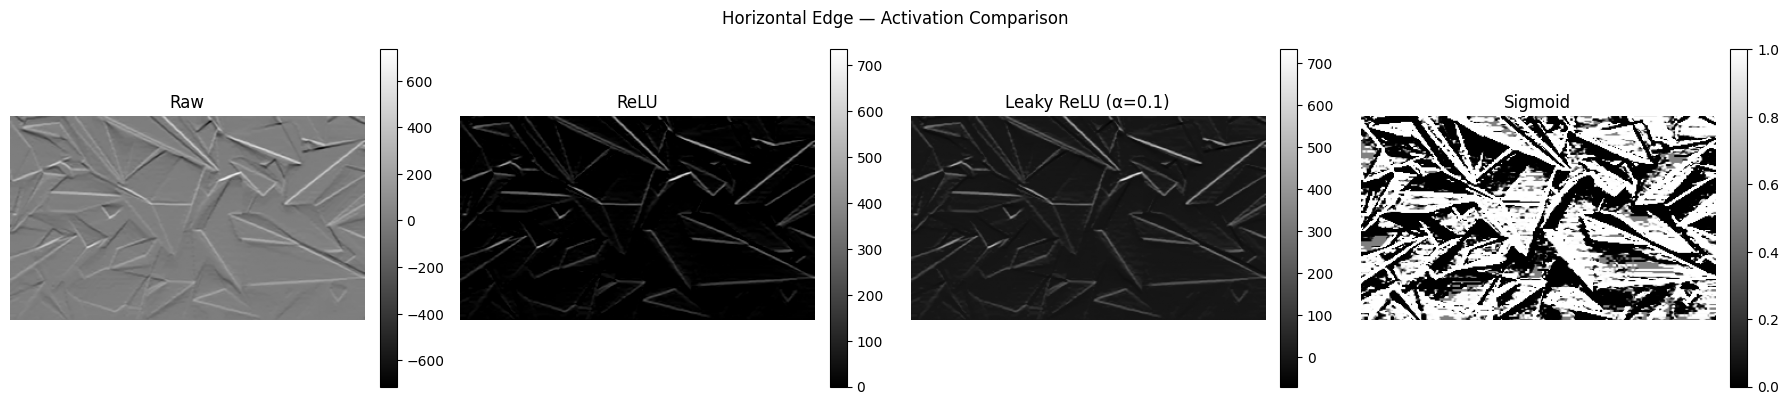


Vertical Edge
Negative raw pixels: 27,947 / 56160 (49.76%)
Zero after ReLU: 31,792 / 56160 (56.61%)
Negative values retained by Leaky ReLU: 27,947
Sigmoid range: 0.0000 to 1.0000


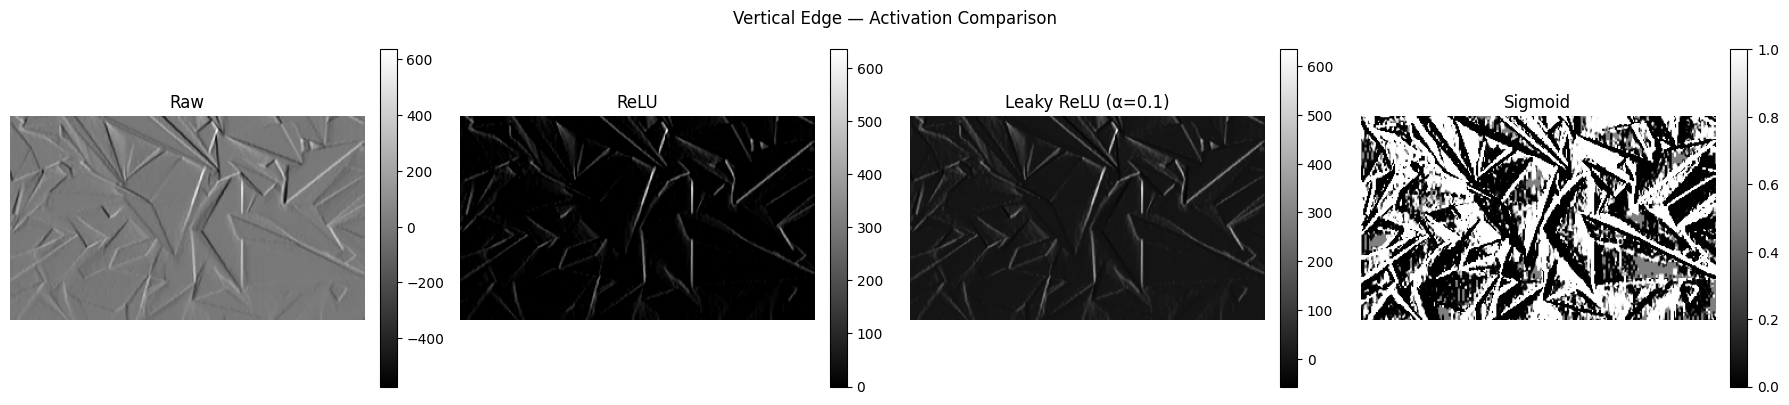

In [10]:
# ============================================================
# CELL 10 — Q1 evidence: ReLU vs Leaky ReLU vs Sigmoid
# ============================================================

def leaky_relu(x, alpha=0.1):
    return np.where(x > 0, x, alpha * x)

def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -50, 50)))

for name in ["Horizontal Edge", "Vertical Edge"]:
    raw = results[name]["A_raw"]
    relu_map = relu(raw)
    leaky_map = leaky_relu(raw, alpha=0.1)
    sigmoid_map = sigmoid(raw)

    print(f"\n{name}")
    print(f"Negative raw pixels: {np.sum(raw < 0):,} / {raw.size} "
          f"({np.mean(raw < 0)*100:.2f}%)")
    print(f"Zero after ReLU: {np.sum(relu_map == 0):,} / {relu_map.size} "
          f"({np.mean(relu_map == 0)*100:.2f}%)")
    print(f"Negative values retained by Leaky ReLU: {np.sum(leaky_map < 0):,}")
    print(f"Sigmoid range: {sigmoid_map.min():.4f} to {sigmoid_map.max():.4f}")

    fig, ax = plt.subplots(1, 4, figsize=(18, 4))
    for a, data, title in zip(
        ax,
        [raw, relu_map, leaky_map, sigmoid_map],
        ["Raw", "ReLU", "Leaky ReLU (α=0.1)", "Sigmoid"]
    ):
        im = a.imshow(data, cmap="gray")
        a.set_title(title)
        a.axis("off")
        fig.colorbar(im, ax=a, fraction=0.046, pad=0.04)

    plt.suptitle(f"{name} — Activation Comparison")
    plt.tight_layout()
    plt.show()


## Q2 — Max Pooling vs Average Pooling

The manual asks you to compare Stage C and Stage D, especially for edge and sharpen filters, and then reason about dark text on a white background.

In [11]:
# ============================================================
# CELL 11 — Q2 evidence: locate strong features and compare pooling
# ============================================================

def top_percent_pixels(x, pct=1):
    threshold = np.percentile(x, 100 - pct)
    return threshold, np.sum(x >= threshold)

for name in ["Horizontal Edge", "Vertical Edge", "Sharpen"]:
    relu_map = results[name]["B_relu"]
    max_map = results[name]["C_maxpool"]
    avg_map = results[name]["D_avgpool"]

    threshold, count = top_percent_pixels(relu_map, pct=1)

    print(f"\n{name}")
    print(f"Top 1% ReLU-response threshold: {threshold:.3f}")
    print(f"Number of top-response pixels: {count}")
    print(f"Max pooling maximum: {max_map.max():.3f}")
    print(f"Average pooling maximum: {avg_map.max():.3f}")
    print(f"Max pooling mean: {max_map.mean():.3f}")
    print(f"Average pooling mean: {avg_map.mean():.3f}")

# Important reasoning aid for dark text on white:
# The custom edge responses depend on the filter orientation/sign.
# The manual asks you to explain the choice from the behavior of the
# pooling operation, not from a memorized one-word answer.
print("\nQ2 reminder:")
print("For dark text on a white background, inspect which pooling method")
print("preserves the relevant text response in YOUR feature map. Use the")
print("actual sign/activation behavior rather than assuming every edge is positive.")



Horizontal Edge
Top 1% ReLU-response threshold: 295.000
Number of top-response pixels: 565
Max pooling maximum: 733.000
Average pooling maximum: 596.500
Max pooling mean: 38.849
Average pooling mean: 23.098

Vertical Edge
Top 1% ReLU-response threshold: 229.000
Number of top-response pixels: 564
Max pooling maximum: 634.000
Average pooling maximum: 483.500
Max pooling mean: 29.766
Average pooling mean: 17.702

Sharpen
Top 1% ReLU-response threshold: 242.000
Number of top-response pixels: 571
Max pooling maximum: 446.000
Average pooling maximum: 274.250
Max pooling mean: 104.056
Average pooling mean: 85.542

Q2 reminder:
For dark text on a white background, inspect which pooling method
preserves the relevant text response in YOUR feature map. Use the
actual sign/activation behavior rather than assuming every edge is positive.


## Q3 — Exact percentage increase

This cell gives the exact percentage increase from Model A to Model B, based on the complete architectures used above.

In [12]:
# ============================================================
# CELL 12 — Q3 exact answer values
# ============================================================

percentage_increase = (
    (audit_b["Total"] - audit_a["Total"]) / audit_a["Total"]
) * 100

print(f"Model A = {audit_a['Total']:,} trainable parameters")
print(f"Model B = {audit_b['Total']:,} trainable parameters")
print(f"Exact percentage increase = {percentage_increase:.2f}%")
print()
print("Same receptive field:")
print("1 × 5×5 conv ≈ 2 × stacked 3×3 convs (stride 1, no dilation).")
print(f"One 5×5 conv: {one_5x5:,} parameters")
print(f"Two 3×3 convs: {stacked_3x3:,} parameters")
print(f"Parameters saved by stacked 3×3 design: {saving:,}")


Model A = 710 trainable parameters
Model B = 1,750 trainable parameters
Exact percentage increase = 146.48%

Same receptive field:
1 × 5×5 conv ≈ 2 × stacked 3×3 convs (stride 1, no dilation).
One 5×5 conv: 1,260 parameters
Two 3×3 convs: 690 parameters
Parameters saved by stacked 3×3 design: 570


## Q4 — Operation order: Conv → ReLU → MaxPool vs Conv → MaxPool → ReLU

The manual asks for a mathematical proof using a 2×2 patch containing negative values.

In [13]:
# ============================================================
# CELL 13 — Q4 mathematical proof with a 2×2 sample patch
# ============================================================

patch = np.array([
    [-5.0,  2.0],
    [ 3.0, -1.0]
])

relu_then_pool = np.max(np.maximum(0, patch))
pool_then_relu = np.maximum(0, np.max(patch))

print("Sample convolution output:")
print(patch)
print()
print("Pipeline 1: ReLU → MaxPool")
print("After ReLU:")
print(np.maximum(0, patch))
print("After MaxPool:", relu_then_pool)
print()
print("Pipeline 2: MaxPool → ReLU")
print("After MaxPool:", np.max(patch))
print("After ReLU:", pool_then_relu)
print()
print("Result:")
print("Both outputs are identical for this 2×2 max-pooling case:",
      np.isclose(relu_then_pool, pool_then_relu))
print()
print("Why this can be computationally useful:")
print("ReLU and max operation commute because max(max(0, x_i)) = max(0, max(x_i)).")
print("However, applying ReLU before pooling can make the intermediate tensor")
print("non-negative before later processing; the main spatial-size computation")
print("reduction still comes from the pooling layer.")


Sample convolution output:
[[-5.  2.]
 [ 3. -1.]]

Pipeline 1: ReLU → MaxPool
After ReLU:
[[0. 2.]
 [3. 0.]]
After MaxPool: 3.0

Pipeline 2: MaxPool → ReLU
After MaxPool: 3.0
After ReLU: 3.0

Result:
Both outputs are identical for this 2×2 max-pooling case: True

Why this can be computationally useful:
ReLU and max operation commute because max(max(0, x_i)) = max(0, max(x_i)).
However, applying ReLU before pooling can make the intermediate tensor
non-negative before later processing; the main spatial-size computation
reduction still comes from the pooling layer.


## Q5 — Filter redundancy / filter collapse

The manual asks for two distinct architectural or optimization root causes and a concrete fix for each.

The code below is a simple diagnostic for the generated filters only. For a real trained CNN, you would inspect the learned kernels/feature maps and training behavior.

In [14]:
# ============================================================
# CELL 14 — Q5 diagnostic aid
# ============================================================

# Similarity between the five hand-crafted feature maps after ReLU.
# This is NOT a trained-CNN diagnosis; it is only an evidence/understanding aid.
names = list(results.keys())
features = [results[n]["B_relu"].flatten() for n in names]

corr = np.corrcoef(features)

print("Correlation matrix of the five Post-ReLU feature maps:")
print("Rows/columns:", names)
print(np.round(corr, 3))

print("\nFor the actual Q5 answer, discuss TWO distinct causes such as:")
print("1) Poor/symmetric initialization → use a suitable random initializer")
print("   such as He initialization for ReLU networks.")
print("2) Dead ReLUs caused by unsuitable optimization/large negative bias")
print("   → adjust learning rate/bias initialization and monitor activation statistics.")
print()
print("Your report should state the cause AND a concrete fix for each.")


Correlation matrix of the five Post-ReLU feature maps:
Rows/columns: ['Horizontal Edge', 'Vertical Edge', 'Sharpen', 'Box Blur', 'Emboss']
[[1.    0.209 0.051 0.01  0.544]
 [0.209 1.    0.048 0.013 0.486]
 [0.051 0.048 1.    0.877 0.595]
 [0.01  0.013 0.877 1.    0.619]
 [0.544 0.486 0.595 0.619 1.   ]]

For the actual Q5 answer, discuss TWO distinct causes such as:
1) Poor/symmetric initialization → use a suitable random initializer
   such as He initialization for ReLU networks.
2) Dead ReLUs caused by unsuitable optimization/large negative bias
   → adjust learning rate/bias initialization and monitor activation statistics.

Your report should state the cause AND a concrete fix for each.


# Final Lab Checklist

Before submission, make sure you have:

- [ ] Your name, roll number, course/section and date
- [ ] One clear input image
- [ ] Five custom 3×3 kernels
- [ ] Stage A: Raw convolution outputs
- [ ] Stage B: ReLU outputs
- [ ] Stage C: 2×2 Max Pooling outputs
- [ ] Stage D: 2×2 Average Pooling outputs
- [ ] Required **5×4 visualization grid** with titles and colorbars
- [ ] Model A code and `model.summary()` screenshot
- [ ] Model B code and `model.summary()` screenshot
- [ ] Hand-written/manual parameter calculations
- [ ] Exact percentage comparison
- [ ] Receptive-field calculation and parameter-saving calculation
- [ ] Answers to Questions 1–5 based on your generated evidence
- [ ] Understanding of all results for the viva

**Important:** The lab manual gives the most weight to Critical Analysis & Viva Defense (55%), so do not submit only the code. Be able to explain what each stage does and why your own feature maps look the way they do.